## 1. Instalação das dependências

In [ ]:

%pip uninstall -y torchao -q
%pip install -q -U "transformers>=4.56.2" "peft>=0.17.1" \
    "accelerate>=1.10.0" "huggingface_hub>=0.34.0" \
    "scikit-learn>=1.4.0" "pandas>=2.0.0"


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.6/11.6 MB 188.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 771.9/771.9 kB 89.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 199.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.0/11.0 MB 180.7 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.2, but you have pandas 3.0.5 which is incompatible.
cudf-cu12 26.2.1 requires pandas<2.4.0,>=2.0, but you have pandas 3.0.5 which is incompatible.
dask-cudf-cu12 26.2.1 requires pandas<2.4.0,>=2.0, but you have pandas 3.0.5 which is incompatible.


## 2. Importações, Google Drive e autenticação

In [ ]:

import os
import gc
import hashlib
import json
import math
import random
import shutil
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True

import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

from sklearn.metrics import (
    accuracy_score,
    ConfusionMatrixDisplay,
    auc,
    confusion_matrix,
    precision_recall_fscore_support,
    precision_recall_curve,
    roc_auc_score,
)
from sklearn.preprocessing import label_binarize
from tqdm.auto import tqdm

from transformers import AutoImageProcessor, AutoModel
from peft import LoraConfig, PeftModel, get_peft_model
from huggingface_hub import notebook_login

from google.colab import drive

print("PyTorch:", torch.__version__)
print("CUDA disponível:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


PyTorch: 2.11.0+cu128
CUDA disponível: True
GPU: NVIDIA RTX PRO 6000 Blackwell Server Edition


In [ ]:

drive.mount("/content/drive")


Mounted at /content/drive


In [ ]:

notebook_login()


## 3. Configuração central

In [ ]:

MODEL_SIZE = "base"

MODEL_IDS = {
    "small": "facebook/dinov3-vits16-pretrain-lvd1689m",
    "base":  "facebook/dinov3-vitb16-pretrain-lvd1689m",
    "large": "facebook/dinov3-vitl16-pretrain-lvd1689m",
}

if MODEL_SIZE not in MODEL_IDS:
    raise ValueError(f"MODEL_SIZE deve ser uma destas opções: {list(MODEL_IDS)}")

MODEL_ID = MODEL_IDS[MODEL_SIZE]


DRIVE_DATA_DIR = Path(
    "/content/drive/MyDrive/perfect_balanced_dataset_wagner_v4_1000"
)


COPY_DATA_TO_LOCAL = True
LOCAL_DATA_DIR = Path("/content/perfect_balanced_dataset_wagner_v4_1000")


EXPERIMENT_NAME = "lora_qv_r8_warmup_v3_stable_large"
OUTPUT_DIR = Path(
    "/content/drive/MyDrive/resultados_dinov3_lora_wagner"
) / MODEL_SIZE / EXPERIMENT_NAME

SPLIT_DIRS = {
    "train": "treino",
    "val": "validacao",
    "test": "teste",
}

EXPECTED_CLASSES = [
    "Grade 0",
    "Grade 1",
    "Grade 2",
    "Grade 3",
    "Grade 4",
    "Grade 5",
    "Normal(Healthy skin)",
]

IMAGE_SIZE = 224
NUM_CLASSES = len(EXPECTED_CLASSES)


DEFAULT_BATCH_SIZE = {
    "small": 32,
    "base": 32,
    "large": 32,
}
DEFAULT_GRAD_ACCUM = {
    "small": 1,
    "base": 1,
    "large": 8,
}

BATCH_SIZE = DEFAULT_BATCH_SIZE[MODEL_SIZE]
GRAD_ACCUM_STEPS = DEFAULT_GRAD_ACCUM[MODEL_SIZE]
NUM_WORKERS = 4

EPOCHS = 50
PATIENCE = 10
MIN_DELTA = 1e-4


HEAD_WARMUP_EPOCHS = 3


LR_LORA = {
    "small": 5e-5,
    "base": 5e-5,
    "large": 1e-5,
}[MODEL_SIZE]

LR_HEAD = {
    "small": 5e-5,
    "base": 5e-5,
    "large": 5e-5,
}[MODEL_SIZE]
WEIGHT_DECAY = 5e-4


LR_SCHEDULER_FACTOR = 0.5
LR_SCHEDULER_PATIENCE = 2
MIN_LR = 1e-6


LORA_RANK = 16
LORA_ALPHA = 32
LORA_DROPOUT = 0.20
LORA_TARGET_MODULES = [
    "q_proj",
    "v_proj",
    "k_proj",
    "o_proj",
    "up_proj",
    "down_proj",
]

CLASSIFIER_DROPOUT = 0.30
LABEL_SMOOTHING = 0.05

USE_AMP = True


PREFER_BFLOAT16 = True


MODEL_LOAD_DTYPE = torch.float32

USE_GRADIENT_CHECKPOINTING = MODEL_SIZE == "large"
MAX_GRAD_NORM = 1.0


CHECK_NUMERICAL_STABILITY = True
SEED = 42


VERIFY_ALL_IMAGES = False

CHECK_EXACT_DUPLICATES_ACROSS_SPLITS = True
FAIL_ON_EXACT_DUPLICATES = False

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Modelo:", MODEL_ID)
print("Experimento:", EXPERIMENT_NAME)
print("Batch size:", BATCH_SIZE)
print("Acumulação de gradientes:", GRAD_ACCUM_STEPS)
print("Batch efetivo:", BATCH_SIZE * GRAD_ACCUM_STEPS)
print("LoRA target modules:", LORA_TARGET_MODULES)
print("LoRA rank/alpha/dropout:", LORA_RANK, LORA_ALPHA, LORA_DROPOUT)
print("Aquecimento da cabeça:", HEAD_WARMUP_EPOCHS, "época(s)")
print("Saída:", OUTPUT_DIR)


Modelo: facebook/dinov3-vitb16-pretrain-lvd1689m
Experimento: lora_qv_r8_warmup_v3_stable_large
Batch size: 32
Acumulação de gradientes: 1
Batch efetivo: 32
LoRA target modules: ['q_proj', 'v_proj', 'k_proj', 'o_proj', 'up_proj', 'down_proj']
LoRA rank/alpha/dropout: 16 32 0.2
Aquecimento da cabeça: 3 época(s)
Saída: /content/drive/MyDrive/resultados_dinov3_lora_wagner/base/lora_qv_r8_warmup_v3_stable_large


## 4. Reprodutibilidade e preparação dos dados

In [ ]:

def seed_everything(seed: int = 42) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    # Configuração reprodutível. Pode reduzir um pouco a velocidade.
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    # TF32 acelera multiplicações em GPUs compatíveis sem alterar a API.
    if torch.cuda.is_available():
        torch.backends.cuda.matmul.allow_tf32 = True

seed_everything(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type != "cuda":
    raise RuntimeError(
        "Este notebook foi preparado para GPU. No Colab, selecione "
        "Ambiente de execução > Alterar tipo de ambiente de execução > GPU."
    )

print("Dispositivo:", DEVICE)


if USE_AMP and DEVICE.type == "cuda":
    bf16_available = bool(torch.cuda.is_bf16_supported())
    AMP_DTYPE = (
        torch.bfloat16
        if PREFER_BFLOAT16 and bf16_available
        else torch.float16
    )
else:
    AMP_DTYPE = torch.float32


SCALER_ENABLED = (
    USE_AMP
    and DEVICE.type == "cuda"
    and AMP_DTYPE == torch.float16
)

print("Tipo dos pesos carregados:", MODEL_LOAD_DTYPE)
print("Tipo usado pelo autocast:", AMP_DTYPE)
print("GradScaler ativado:", SCALER_ENABLED)


Dispositivo: cuda
Tipo dos pesos carregados: torch.float32
Tipo usado pelo autocast: torch.bfloat16
GradScaler ativado: False


In [ ]:

def validate_dataset_structure(root: Path) -> None:
    if not root.exists():
        raise FileNotFoundError(
            f"Pasta não encontrada: {root}\n"
            "Confira se o Google Drive foi montado e se o caminho está correto."
        )

    for split_key, split_folder in SPLIT_DIRS.items():
        split_path = root / split_folder

        if not split_path.exists():
            raise FileNotFoundError(
                f"Pasta do conjunto '{split_key}' não encontrada: {split_path}"
            )

        present_classes = sorted(
            p.name for p in split_path.iterdir() if p.is_dir()
        )
        missing = sorted(set(EXPECTED_CLASSES) - set(present_classes))
        extra = sorted(set(present_classes) - set(EXPECTED_CLASSES))

        if missing:
            raise ValueError(
                f"Classes ausentes em {split_path}: {missing}"
            )
        if extra:
            print(f"Aviso: pastas adicionais em {split_path}: {extra}")

        count = sum(
            1 for p in split_path.rglob("*")
            if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg"}
        )
        print(f"{split_key:>5}: {count:5d} imagens em {split_path}")

validate_dataset_structure(DRIVE_DATA_DIR)


train:  4900 imagens em /content/drive/MyDrive/perfect_balanced_dataset_wagner_v4_1000/treino
  val:  1050 imagens em /content/drive/MyDrive/perfect_balanced_dataset_wagner_v4_1000/validacao
 test:  1050 imagens em /content/drive/MyDrive/perfect_balanced_dataset_wagner_v4_1000/teste


In [ ]:

if COPY_DATA_TO_LOCAL:
    if LOCAL_DATA_DIR.exists():
        print("A cópia local já existe:", LOCAL_DATA_DIR)
    else:
        print("Copiando o dataset do Google Drive para o disco local...")
        shutil.copytree(DRIVE_DATA_DIR, LOCAL_DATA_DIR)

    DATA_DIR = LOCAL_DATA_DIR
else:
    DATA_DIR = DRIVE_DATA_DIR

print("Dataset ativo:", DATA_DIR)


Copiando o dataset do Google Drive para o disco local...
Dataset ativo: /content/perfect_balanced_dataset_wagner_v4_1000


In [ ]:

def sha256_file(path: Path, chunk_size: int = 1024 * 1024) -> str:
    digest = hashlib.sha256()
    with open(path, "rb") as file:
        while chunk := file.read(chunk_size):
            digest.update(chunk)
    return digest.hexdigest()


def find_exact_cross_split_duplicates(root: Path) -> pd.DataFrame:
    records = []

    for split_key, split_folder in SPLIT_DIRS.items():
        split_root = root / split_folder
        image_paths = sorted(
            p for p in split_root.rglob("*")
            if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg"}
        )

        for path in tqdm(image_paths, desc=f"Hashes: {split_key}"):
            records.append({
                "hash": sha256_file(path),
                "split": split_key,
                "classe": path.parent.name,
                "arquivo": str(path),
            })

    hashes_df = pd.DataFrame(records)
    split_count = hashes_df.groupby("hash")["split"].nunique()
    duplicated_hashes = split_count[split_count > 1].index

    return (
        hashes_df[hashes_df["hash"].isin(duplicated_hashes)]
        .sort_values(["hash", "split", "arquivo"])
        .reset_index(drop=True)
    )


if CHECK_EXACT_DUPLICATES_ACROSS_SPLITS:
    cross_split_duplicates_df = find_exact_cross_split_duplicates(DATA_DIR)

    if cross_split_duplicates_df.empty:
        print("Nenhuma duplicata exata encontrada entre os splits.")
    else:
        n_hashes = cross_split_duplicates_df["hash"].nunique()
        print(
            f"ATENÇÃO: {n_hashes} imagem(ns) distinta(s) aparecem em mais "
            "de um split. Isso pode causar vazamento de dados."
        )
        display(cross_split_duplicates_df.head(50))

        duplicate_report_path = OUTPUT_DIR / "exact_duplicates_across_splits.csv"
        cross_split_duplicates_df.to_csv(duplicate_report_path, index=False)
        print("Relatório salvo em:", duplicate_report_path)

        if FAIL_ON_EXACT_DUPLICATES:
            raise RuntimeError(
                "Foram encontradas duplicatas exatas entre os splits. "
                "Corrija a separação dos dados antes do treinamento."
            )


Hashes: train:   0%|          | 0/4900 [00:00<?, ?it/s]

Hashes: val:   0%|          | 0/1050 [00:00<?, ?it/s]

Hashes: test:   0%|          | 0/1050 [00:00<?, ?it/s]

ATENÇÃO: 185 imagem(ns) distinta(s) aparecem em mais de um split. Isso pode causar vazamento de dados.


,hash,split,classe,arquivo
0,024526d7375fbb857588e09905f1b7e16bc4cf9fb0ed2e...,train,Grade 2,/content/perfect_balanced_dataset_wagner_v4_10...
1,024526d7375fbb857588e09905f1b7e16bc4cf9fb0ed2e...,val,Grade 1,/content/perfect_balanced_dataset_wagner_v4_10...
2,03c8cf1567d143337eddbc39eec6a9ad48e001510fbb5d...,test,Normal(Healthy skin),/content/perfect_balanced_dataset_wagner_v4_10...
3,03c8cf1567d143337eddbc39eec6a9ad48e001510fbb5d...,train,Normal(Healthy skin),/content/perfect_balanced_dataset_wagner_v4_10...
4,03c8cf1567d143337eddbc39eec6a9ad48e001510fbb5d...,val,Normal(Healthy skin),/content/perfect_balanced_dataset_wagner_v4_10...
5,03c8cf1567d143337eddbc39eec6a9ad48e001510fbb5d...,val,Normal(Healthy skin),/content/perfect_balanced_dataset_wagner_v4_10...
6,06e6438e86e80bc61248c3857ed094c422440025420e07...,test,Normal(Healthy skin),/content/perfect_balanced_dataset_wagner_v4_10...
7,06e6438e86e80bc61248c3857ed094c422440025420e07...,val,Normal(Healthy skin),/content/perfect_balanced_dataset_wagner_v4_10...
8,089ab6bd8564f3a19d8f7459eef7d39d463ad2a96d50c1...,train,Normal(Healthy skin),/content/perfect_balanced_dataset_wagner_v4_10...
9,089ab6bd8564f3a19d8f7459eef7d39d463ad2a96d50c1...,train,Normal(Healthy skin),/content/perfect_balanced_dataset_wagner_v4_10...


Relatório salvo em: /content/drive/MyDrive/resultados_dinov3_lora_wagner/base/lora_qv_r8_warmup_v3_stable_large/exact_duplicates_across_splits.csv


In [ ]:

def inspect_image_sizes(root: Path, max_images_per_split: int = 200) -> None:
    print("Resoluções encontradas em uma amostra dos arquivos:")
    for split_key, split_folder in SPLIT_DIRS.items():
        files = sorted((root / split_folder).rglob("*.jpg"))
        sizes = Counter()

        for path in files[:max_images_per_split]:
            try:
                with Image.open(path) as img:
                    sizes[img.size] += 1
            except Exception as exc:
                print(f"Falha ao abrir {path}: {exc}")

        print(f"{split_key:>5}: {sizes.most_common(5)}")

inspect_image_sizes(DATA_DIR)
print(
    "\nIndependentemente da resolução original, todas as imagens serão "
    f"convertidas para {IMAGE_SIZE}x{IMAGE_SIZE}."
)


Resoluções encontradas em uma amostra dos arquivos:
train: [((224, 224), 200)]
  val: [((224, 224), 182), ((227, 227), 18)]
 test: [((224, 224), 200)]

Independentemente da resolução original, todas as imagens serão convertidas para 224x224.


In [ ]:

def find_corrupted_images(root: Path) -> list[Path]:
    corrupted = []
    image_paths = [
        p for p in root.rglob("*")
        if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg"}
    ]

    for path in tqdm(image_paths, desc="Verificando imagens"):
        try:
            with Image.open(path) as img:
                img.verify()
        except Exception:
            corrupted.append(path)

    return corrupted

if VERIFY_ALL_IMAGES:
    corrupted_images = find_corrupted_images(DATA_DIR)
    print("Arquivos corrompidos:", len(corrupted_images))
    for path in corrupted_images[:20]:
        print(path)

    if corrupted_images:
        raise RuntimeError(
            "Há imagens corrompidas. Corrija ou remova os arquivos listados."
        )


## 5. Transformações, datasets e DataLoaders

In [ ]:


image_processor = AutoImageProcessor.from_pretrained(MODEL_ID)

IMAGE_MEAN = image_processor.image_mean
IMAGE_STD = image_processor.image_std

print("Média de normalização:", IMAGE_MEAN)
print("Desvio-padrão:", IMAGE_STD)


preprocessor_config.json:   0%|          | 0.00/585 [00:00<?, ?B/s]

Média de normalização: (0.485, 0.456, 0.406)
Desvio-padrão: (0.229, 0.224, 0.225)


In [ ]:

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    # transforms.ColorJitter(
    #     brightness=0.10,
    #     contrast=0.10,
    #     saturation=0.08,
    #     hue=0.02,
    # ),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGE_MEAN, std=IMAGE_STD),
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGE_MEAN, std=IMAGE_STD),
])


In [ ]:

train_dataset = datasets.ImageFolder(
    DATA_DIR / SPLIT_DIRS["train"],
    transform=train_transform,
)


train_eval_dataset = datasets.ImageFolder(
    DATA_DIR / SPLIT_DIRS["train"],
    transform=eval_transform,
)

val_dataset = datasets.ImageFolder(
    DATA_DIR / SPLIT_DIRS["val"],
    transform=eval_transform,
)
test_dataset = datasets.ImageFolder(
    DATA_DIR / SPLIT_DIRS["test"],
    transform=eval_transform,
)


if set(train_dataset.classes) != set(EXPECTED_CLASSES):
    raise ValueError(
        f"Classes encontradas: {train_dataset.classes}\n"
        f"Classes esperadas: {EXPECTED_CLASSES}"
    )

if train_dataset.class_to_idx != train_eval_dataset.class_to_idx:
    raise ValueError(
        "O mapeamento de classes difere entre treino e treino determinístico."
    )
if train_dataset.class_to_idx != val_dataset.class_to_idx:
    raise ValueError("O mapeamento de classes difere entre treino e validação.")
if train_dataset.class_to_idx != test_dataset.class_to_idx:
    raise ValueError("O mapeamento de classes difere entre treino e teste.")

CLASS_NAMES = train_dataset.classes
CLASS_TO_IDX = train_dataset.class_to_idx
IDX_TO_CLASS = {idx: name for name, idx in CLASS_TO_IDX.items()}

print("Mapeamento de classes:")
for name, idx in CLASS_TO_IDX.items():
    print(f"  {idx}: {name}")

print("\nTamanhos:")
print("Treino:", len(train_dataset))
print("Validação:", len(val_dataset))
print("Teste:", len(test_dataset))


Mapeamento de classes:
  0: Grade 0
  1: Grade 1
  2: Grade 2
  3: Grade 3
  4: Grade 4
  5: Grade 5
  6: Normal(Healthy skin)

Tamanhos:
Treino: 4900
Validação: 1050
Teste: 1050


In [ ]:

def class_counts(dataset) -> pd.DataFrame:
    counts = Counter(dataset.targets)
    return pd.DataFrame({
        "classe": [IDX_TO_CLASS[i] for i in range(NUM_CLASSES)],
        "quantidade": [counts.get(i, 0) for i in range(NUM_CLASSES)],
    })

print("Treino")
display(class_counts(train_dataset))

print("Validação")
display(class_counts(val_dataset))

print("Teste")
display(class_counts(test_dataset))


Treino


,classe,quantidade
0,Grade 0,700
1,Grade 1,700
2,Grade 2,700
3,Grade 3,700
4,Grade 4,700
5,Grade 5,700
6,Normal(Healthy skin),700


Validação


,classe,quantidade
0,Grade 0,150
1,Grade 1,150
2,Grade 2,150
3,Grade 3,150
4,Grade 4,150
5,Grade 5,150
6,Normal(Healthy skin),150


Teste


,classe,quantidade
0,Grade 0,150
1,Grade 1,150
2,Grade 2,150
3,Grade 3,150
4,Grade 4,150
5,Grade 5,150
6,Normal(Healthy skin),150


In [ ]:

generator = torch.Generator()
generator.manual_seed(SEED)

loader_kwargs = {
    "batch_size": BATCH_SIZE,
    "num_workers": NUM_WORKERS,
    "pin_memory": True,
    "persistent_workers": NUM_WORKERS > 0,
}

train_loader = DataLoader(
    train_dataset,
    shuffle=True,
    generator=generator,
    **loader_kwargs,
)

train_eval_loader = DataLoader(
    train_eval_dataset,
    shuffle=False,
    **loader_kwargs,
)

val_loader = DataLoader(
    val_dataset,
    shuffle=False,
    **loader_kwargs,
)
test_loader = DataLoader(
    test_dataset,
    shuffle=False,
    **loader_kwargs,
)

images, labels = next(iter(train_loader))
print("Formato do lote de imagens:", images.shape)
print("Formato dos rótulos:", labels.shape)


Formato do lote de imagens: torch.Size([32, 3, 224, 224])
Formato dos rótulos: torch.Size([32])


## 6. DINOv3 com adaptadores LoRA

In [ ]:

class DINOv3LoRAClassifier(nn.Module):
    def __init__(
        self,
        backbone: nn.Module,
        hidden_size: int,
        num_classes: int,
        dropout: float = 0.2,
    ):
        super().__init__()
        self.backbone = backbone
        self.classifier = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(hidden_size, num_classes),
        )

    def forward(self, pixel_values: torch.Tensor) -> torch.Tensor:
        outputs = self.backbone(pixel_values=pixel_values)


        if getattr(outputs, "pooler_output", None) is not None:
            features = outputs.pooler_output
        else:
            features = outputs.last_hidden_state[:, 0, :]


        features = features.float()

        with torch.autocast(
            device_type=features.device.type,
            enabled=False,
        ):
            logits = self.classifier(features)

        return logits


def build_model() -> DINOv3LoRAClassifier:
    backbone = AutoModel.from_pretrained(
        MODEL_ID,
        torch_dtype=MODEL_LOAD_DTYPE,
    )

    hidden_size = backbone.config.hidden_size

    if USE_GRADIENT_CHECKPOINTING:
        backbone.gradient_checkpointing_enable()
        if hasattr(backbone, "enable_input_require_grads"):
            backbone.enable_input_require_grads()

    lora_config = LoraConfig(
        r=LORA_RANK,
        lora_alpha=LORA_ALPHA,
        lora_dropout=LORA_DROPOUT,
        target_modules=LORA_TARGET_MODULES,
        bias="none",
        inference_mode=False,
    )

    backbone = get_peft_model(backbone, lora_config)

    model = DINOv3LoRAClassifier(
        backbone=backbone,
        hidden_size=hidden_size,
        num_classes=NUM_CLASSES,
        dropout=CLASSIFIER_DROPOUT,
    )

    return model


model = build_model().to(DEVICE)

# Mostra os parâmetros treináveis do backbone LoRA.
model.backbone.print_trainable_parameters()

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"\nParâmetros totais: {total_params:,}")
print(f"Parâmetros treináveis, incluindo a cabeça: {trainable_params:,}")
print(f"Percentual treinável: {100 * trainable_params / total_params:.4f}%")


config.json:   0%|          | 0.00/744 [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B /  343MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

trainable params: 2,654,208 || all params: 88,314,624 || trainable%: 3.0054

Parâmetros totais: 88,320,007
Parâmetros treináveis, incluindo a cabeça: 2,659,591
Percentual treinável: 3.0113%


In [ ]:

# Teste rápido da passagem direta.
model.eval()

with torch.inference_mode():
    sample_images = images[:2].to(DEVICE, non_blocking=True)

    with torch.autocast(
        device_type=DEVICE.type,
        dtype=AMP_DTYPE,
        enabled=USE_AMP,
    ):
        sample_logits = model(sample_images)

print("Formato da saída:", sample_logits.shape)
print("Dtype das imagens:", sample_images.dtype)
print("Dtype da saída:", sample_logits.dtype)
assert sample_logits.shape == (2, NUM_CLASSES)
assert torch.isfinite(sample_logits).all(), (
    "O teste direto produziu NaN/Inf. Tente USE_AMP=False para diagnóstico."
)

del sample_images, sample_logits
gc.collect()
torch.cuda.empty_cache()


Formato da saída: torch.Size([2, 7])
Dtype das imagens: torch.float32
Dtype da saída: torch.float32


## 7. Precision, recall, F1, AUC-ROC e AUC-PR

In [ ]:

def _safe_binary_auc(
    y_true_binary: np.ndarray,
    y_score: np.ndarray,
) -> tuple[float, float]:
    """Calcula AUC-ROC e a área sob a curva precision-recall."""
    if np.unique(y_true_binary).size < 2:
        return float("nan"), float("nan")

    auc_roc = roc_auc_score(y_true_binary, y_score)

    # AUC-PR verdadeiro: integração numérica de precision em função de recall.
    # Não confundir com Average Precision, que usa outra regra de ponderação.
    precision_curve, recall_curve, _ = precision_recall_curve(
        y_true_binary,
        y_score,
    )
    auc_pr = auc(recall_curve, precision_curve)

    return float(auc_roc), float(auc_pr)


def compute_macro_metrics(
    y_true: list[int],
    y_pred: list[int],
    y_prob: np.ndarray,
) -> dict[str, float]:
    if not np.isfinite(y_prob).all():
        invalid_count = int((~np.isfinite(y_prob)).sum())
        raise FloatingPointError(
            f"As probabilidades contêm {invalid_count} valores NaN/Inf. "
            "O problema surgiu nos logits do modelo, antes do scikit-learn."
        )

    accuracy = accuracy_score(
        y_true,
        y_pred,
    )

    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=list(range(NUM_CLASSES)),
        average="macro",
        zero_division=0,
    )

    y_true_binary = label_binarize(
        y_true,
        classes=list(range(NUM_CLASSES)),
    )

    per_class_auc_roc = []
    per_class_auc_pr = []

    for class_idx in range(NUM_CLASSES):
        auc_roc_value, auc_pr_value = _safe_binary_auc(
            y_true_binary[:, class_idx],
            y_prob[:, class_idx],
        )
        per_class_auc_roc.append(auc_roc_value)
        per_class_auc_pr.append(auc_pr_value)

    return {
        "accuracy": float(accuracy),
        "precision": float(precision),
        "recall": float(recall),
        "f1": float(f1),
        "auc_roc": float(np.nanmean(per_class_auc_roc)),
        "auc_pr": float(np.nanmean(per_class_auc_pr)),
    }


def per_class_metrics_dataframe(
    y_true: list[int],
    y_pred: list[int],
    y_prob: np.ndarray,
) -> pd.DataFrame:
    labels = list(range(NUM_CLASSES))

    precision, recall, f1, support = precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=labels,
        average=None,
        zero_division=0,
    )

    y_true_binary = label_binarize(y_true, classes=labels)
    auc_roc_values = []
    auc_pr_values = []

    for class_idx in labels:
        auc_roc_value, auc_pr_value = _safe_binary_auc(
            y_true_binary[:, class_idx],
            y_prob[:, class_idx],
        )
        auc_roc_values.append(auc_roc_value)
        auc_pr_values.append(auc_pr_value)

    rows = [
        {
            "classe": IDX_TO_CLASS[i],
            "precision": precision[i],
            "recall": recall[i],
            "f1": f1[i],
            "auc_roc": auc_roc_values[i],
            "auc_pr": auc_pr_values[i],
            "suporte": int(support[i]),
        }
        for i in labels
    ]

    macro_metrics = compute_macro_metrics(y_true, y_pred, y_prob)

    auc_roc_array = np.asarray(auc_roc_values, dtype=float)
    auc_pr_array = np.asarray(auc_pr_values, dtype=float)
    support_array = np.asarray(support, dtype=float)

    valid_auc_roc = np.isfinite(auc_roc_array) & (support_array > 0)
    valid_auc_pr = np.isfinite(auc_pr_array) & (support_array > 0)

    weighted_auc_roc = (
        float(np.average(auc_roc_array[valid_auc_roc], weights=support_array[valid_auc_roc]))
        if valid_auc_roc.any()
        else float("nan")
    )
    weighted_auc_pr = (
        float(np.average(auc_pr_array[valid_auc_pr], weights=support_array[valid_auc_pr]))
        if valid_auc_pr.any()
        else float("nan")
    )

    weighted = precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=labels,
        average="weighted",
        zero_division=0,
    )

    rows.extend([
        {
            "classe": "macro avg",
            "precision": macro_metrics["precision"],
            "recall": macro_metrics["recall"],
            "f1": macro_metrics["f1"],
            "auc_roc": macro_metrics["auc_roc"],
            "auc_pr": macro_metrics["auc_pr"],
            "suporte": int(np.sum(support)),
        },
        {
            "classe": "weighted avg",
            "precision": weighted[0],
            "recall": weighted[1],
            "f1": weighted[2],
            "auc_roc": weighted_auc_roc,
            "auc_pr": weighted_auc_pr,
            "suporte": int(np.sum(support)),
        },
    ])

    return pd.DataFrame(rows)


## 8. Laços de treino e avaliação

In [ ]:

criterion = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)


lora_params = []
head_params = []
other_trainable_params = []

for name, parameter in model.named_parameters():
    if "lora_" in name:
        lora_params.append(parameter)
    elif name.startswith("classifier."):
        head_params.append(parameter)
    elif parameter.requires_grad:
        other_trainable_params.append(parameter)

param_groups = [
    {
        "params": lora_params,
        "lr": LR_LORA,
        "weight_decay": WEIGHT_DECAY,
    },
    {
        "params": head_params,
        "lr": LR_HEAD,
        "weight_decay": WEIGHT_DECAY,
    },
]

if other_trainable_params:
    param_groups.append({
        "params": other_trainable_params,
        "lr": LR_LORA,
        "weight_decay": WEIGHT_DECAY,
    })

optimizer = torch.optim.AdamW(param_groups)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=LR_SCHEDULER_FACTOR,
    patience=LR_SCHEDULER_PATIENCE,
    threshold=MIN_DELTA,
    min_lr=MIN_LR,
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=SCALER_ENABLED,
)


def set_lora_trainable(enabled: bool) -> None:
    for name, parameter in model.named_parameters():
        if "lora_" in name:
            parameter.requires_grad = enabled


# Começa treinando somente a cabeça classificadora.
set_lora_trainable(False)

print("Tensores LoRA:", len(lora_params))
print("Tensores da cabeça:", len(head_params))
print("Outros tensores treináveis:", len(other_trainable_params))
print("LoRA inicialmente congelado:", HEAD_WARMUP_EPOCHS > 0)


Tensores LoRA: 144
Tensores da cabeça: 2
Outros tensores treináveis: 0
LoRA inicialmente congelado: True


In [ ]:

def run_epoch(
    model: nn.Module,
    loader: DataLoader,
    optimizer: torch.optim.Optimizer | None = None,
) -> tuple[dict[str, float], list[int], list[int], np.ndarray]:
    is_training = optimizer is not None

    if is_training:
        model.train()
        optimizer.zero_grad(set_to_none=True)
    else:
        model.eval()

    all_targets = []
    all_predictions = []
    all_probabilities = []

    progress = tqdm(
        loader,
        desc="Treino" if is_training else "Avaliação",
        leave=False,
    )

    for step, (pixel_values, targets) in enumerate(progress, start=1):
        pixel_values = pixel_values.to(
            DEVICE,
            non_blocking=True,
        )
        targets = targets.to(
            DEVICE,
            non_blocking=True,
        )

        if CHECK_NUMERICAL_STABILITY and not torch.isfinite(pixel_values).all():
            raise FloatingPointError(
                f"NaN/Inf encontrado nas imagens de entrada, lote {step}."
            )

        with torch.set_grad_enabled(is_training):
            with torch.autocast(
                device_type=DEVICE.type,
                dtype=AMP_DTYPE,
                enabled=USE_AMP,
            ):
                logits = model(pixel_values)

                if CHECK_NUMERICAL_STABILITY and not torch.isfinite(logits).all():
                    finite_logits = logits[torch.isfinite(logits)]
                    finite_range = (
                        (
                            float(finite_logits.min().item()),
                            float(finite_logits.max().item()),
                        )
                        if finite_logits.numel() > 0
                        else None
                    )
                    raise FloatingPointError(
                        f"Logits com NaN/Inf no lote {step}. "
                        f"Faixa dos valores finitos: {finite_range}. "
                        f"AMP_DTYPE={AMP_DTYPE}, modelo={MODEL_SIZE}."
                    )

                loss = criterion(logits, targets)

                if CHECK_NUMERICAL_STABILITY and not torch.isfinite(loss):
                    raise FloatingPointError(
                        f"Loss NaN/Inf no lote {step}. "
                        f"AMP_DTYPE={AMP_DTYPE}, modelo={MODEL_SIZE}."
                    )

                if is_training:
                    loss = loss / GRAD_ACCUM_STEPS

            if is_training:
                scaler.scale(loss).backward()

                should_update = (
                    step % GRAD_ACCUM_STEPS == 0
                    or step == len(loader)
                )

                if should_update:
                    scaler.unscale_(optimizer)
                    grad_norm = torch.nn.utils.clip_grad_norm_(
                        model.parameters(),
                        MAX_GRAD_NORM,
                    )

                    grad_is_finite = bool(torch.isfinite(grad_norm))

                    if SCALER_ENABLED:
                        # O GradScaler detecta gradientes não finitos e pula
                        # automaticamente a atualização do otimizador.
                        scaler.step(optimizer)
                        scaler.update()
                    elif grad_is_finite:
                        optimizer.step()
                    else:
                        print(
                            f"Aviso: atualização ignorada no lote {step} "
                            f"por gradiente não finito: {grad_norm}."
                        )

                    optimizer.zero_grad(set_to_none=True)

        probabilities = torch.softmax(logits.float(), dim=1)

        if CHECK_NUMERICAL_STABILITY and not torch.isfinite(probabilities).all():
            raise FloatingPointError(
                f"Probabilidades com NaN/Inf no lote {step}. "
                "Os logits devem ser inspecionados."
            )

        predictions = probabilities.argmax(dim=1)

        all_targets.extend(targets.detach().cpu().tolist())
        all_predictions.extend(predictions.detach().cpu().tolist())
        all_probabilities.append(probabilities.detach().cpu().numpy())

    all_probabilities = np.concatenate(all_probabilities, axis=0)

    metrics = compute_macro_metrics(
        all_targets,
        all_predictions,
        all_probabilities,
    )

    return (
        metrics,
        all_targets,
        all_predictions,
        all_probabilities,
    )


def print_epoch_metrics(
    epoch: int,
    train_metrics: dict[str, float],
    val_metrics: dict[str, float],
) -> None:
    print(
        f"Época {epoch:03d} | "
        f"Treino: accuracy={train_metrics['accuracy']:.4f}, "
        f"precision={train_metrics['precision']:.4f}, "
        f"recall={train_metrics['recall']:.4f}, "
        f"f1={train_metrics['f1']:.4f}, "
        f"auc_roc={train_metrics['auc_roc']:.4f}, "
        f"auc_pr={train_metrics['auc_pr']:.4f} | "
        f"Validação: accuracy={val_metrics['accuracy']:.4f}, "
        f"precision={val_metrics['precision']:.4f}, "
        f"recall={val_metrics['recall']:.4f}, "
        f"f1={val_metrics['f1']:.4f}, "
        f"auc_roc={val_metrics['auc_roc']:.4f}, "
        f"auc_pr={val_metrics['auc_pr']:.4f}"
    )


## 9. Treinamento com redução de LR e early stopping pelo F1 macro

In [ ]:

BEST_CHECKPOINT_PATH = OUTPUT_DIR / "best_trainable_checkpoint.pt"
HISTORY_PATH = OUTPUT_DIR / "history.csv"

history = []
best_val_f1 = -math.inf
epochs_without_improvement = 0

for epoch in range(1, EPOCHS + 1):
    in_head_warmup = epoch <= HEAD_WARMUP_EPOCHS

    if epoch == HEAD_WARMUP_EPOCHS + 1:
        set_lora_trainable(True)
        epochs_without_improvement = 0
        print("\nLoRA ativado: início da adaptação do backbone.\n")

    phase_name = "aquecimento da cabeça" if in_head_warmup else "LoRA + cabeça"

    train_metrics, _, _, _ = run_epoch(
        model=model,
        loader=train_loader,
        optimizer=optimizer,
    )

    with torch.inference_mode():
        val_metrics, _, _, _ = run_epoch(
            model=model,
            loader=val_loader,
            optimizer=None,
        )

    current_lr_lora = optimizer.param_groups[0]["lr"]
    current_lr_head = optimizer.param_groups[1]["lr"]

    row = {
        "epoch": epoch,
        "phase": phase_name,
        "lr_lora": current_lr_lora,
        "lr_head": current_lr_head,
        "train_accuracy": train_metrics["accuracy"],
        "train_precision": train_metrics["precision"],
        "train_recall": train_metrics["recall"],
        "train_f1": train_metrics["f1"],
        "train_auc_roc": train_metrics["auc_roc"],
        "train_auc_pr": train_metrics["auc_pr"],
        "val_accuracy": val_metrics["accuracy"],
        "val_precision": val_metrics["precision"],
        "val_recall": val_metrics["recall"],
        "val_f1": val_metrics["f1"],
        "val_auc_roc": val_metrics["auc_roc"],
        "val_auc_pr": val_metrics["auc_pr"],
    }
    history.append(row)

    history_df = pd.DataFrame(history)
    history_df.to_csv(HISTORY_PATH, index=False)

    print(f"Fase: {phase_name}")
    print_epoch_metrics(epoch, train_metrics, val_metrics)
    print(
        f"  LR LoRA={current_lr_lora:.2e} | "
        f"LR cabeça={current_lr_head:.2e}"
    )

    if val_metrics["f1"] > best_val_f1 + MIN_DELTA:
        best_val_f1 = val_metrics["f1"]
        epochs_without_improvement = 0

        # Salva sempre LoRA e cabeça. Isso é importante quando o melhor
        # checkpoint ocorre durante o aquecimento, com LoRA congelado.
        adapter_and_head_state = {
            name: parameter.detach().cpu().clone()
            for name, parameter in model.named_parameters()
            if "lora_" in name or name.startswith("classifier.")
        }

        torch.save(
            {
                "epoch": epoch,
                "phase": phase_name,
                "best_val_f1": best_val_f1,
                "best_val_metrics": val_metrics,
                "model_size": MODEL_SIZE,
                "model_id": MODEL_ID,
                "class_to_idx": CLASS_TO_IDX,
                "state_dict": adapter_and_head_state,
            },
            BEST_CHECKPOINT_PATH,
        )

        print(f"  Novo melhor checkpoint: F1={best_val_f1:.4f}")
    else:
        epochs_without_improvement += 1
        print(
            f"  Sem melhora por "
            f"{epochs_without_improvement}/{PATIENCE} época(s)."
        )

    # O scheduler só começa a atuar quando os adaptadores são ativados.
    if not in_head_warmup:
        scheduler.step(val_metrics["f1"])

    if not in_head_warmup and epochs_without_improvement >= PATIENCE:
        print("Early stopping acionado.")
        break

print(f"\nMelhor F1 macro de validação: {best_val_f1:.4f}")
print("Checkpoint:", BEST_CHECKPOINT_PATH)


Treino:   0%|          | 0/154 [00:00<?, ?it/s]

Avaliação:   0%|          | 0/33 [00:00<?, ?it/s]

Fase: aquecimento da cabeça
Época 001 | Treino: accuracy=0.3322, precision=0.3419, recall=0.3322, f1=0.3240, auc_roc=0.7180, auc_pr=0.3393 | Validação: accuracy=0.5876, precision=0.6161, recall=0.5876, f1=0.5853, auc_roc=0.8768, auc_pr=0.6210
  LR LoRA=5.00e-05 | LR cabeça=5.00e-05
  Novo melhor checkpoint: F1=0.5853


Treino:   0%|          | 0/154 [00:00<?, ?it/s]

Avaliação:   0%|          | 0/33 [00:00<?, ?it/s]

Fase: aquecimento da cabeça
Época 002 | Treino: accuracy=0.6147, precision=0.6153, recall=0.6147, f1=0.6133, auc_roc=0.8964, auc_pr=0.6415 | Validação: accuracy=0.7295, precision=0.7608, recall=0.7295, f1=0.7287, auc_roc=0.9366, auc_pr=0.7760
  LR LoRA=5.00e-05 | LR cabeça=5.00e-05
  Novo melhor checkpoint: F1=0.7287


... (44 outputs left out)

Fase: LoRA + cabeça
Época 017 | Treino: accuracy=0.9818, precision=0.9818, recall=0.9818, f1=0.9818, auc_roc=0.9996, auc_pr=0.9980 | Validação: accuracy=0.8705, precision=0.8745, recall=0.8705, f1=0.8697, auc_roc=0.9664, auc_pr=0.8601
  LR LoRA=1.25e-05 | LR cabeça=1.25e-05
  Sem melhora por 9/10 época(s).


Treino:   0%|          | 0/154 [00:00<?, ?it/s]

Avaliação:   0%|          | 0/33 [00:00<?, ?it/s]

Fase: LoRA + cabeça
Época 018 | Treino: accuracy=0.9822, precision=0.9823, recall=0.9822, f1=0.9821, auc_roc=0.9996, auc_pr=0.9975 | Validação: accuracy=0.8705, precision=0.8745, recall=0.8705, f1=0.8692, auc_roc=0.9633, auc_pr=0.8558
  LR LoRA=6.25e-06 | LR cabeça=6.25e-06
  Sem melhora por 10/10 época(s).
Early stopping acionado.

Melhor F1 macro de validação: 0.8806
Checkpoint: /content/drive/MyDrive/resultados_dinov3_lora_wagner/base/lora_qv_r8_warmup_v3_stable_large/best_trainable_checkpoint.pt


## 10. Curvas das métricas monitoradas

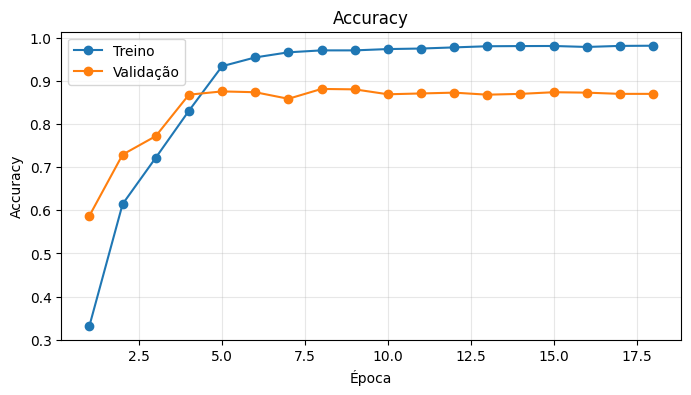

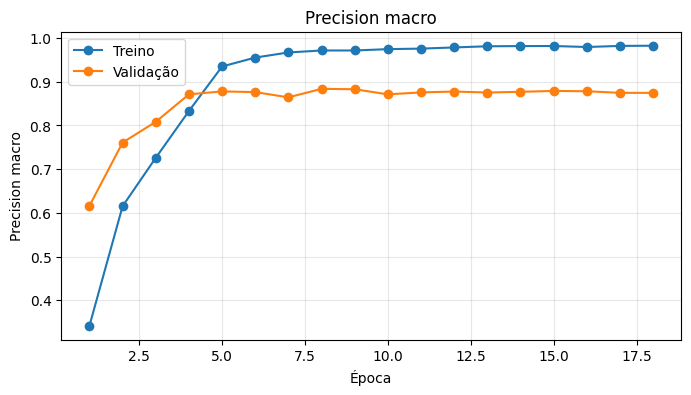

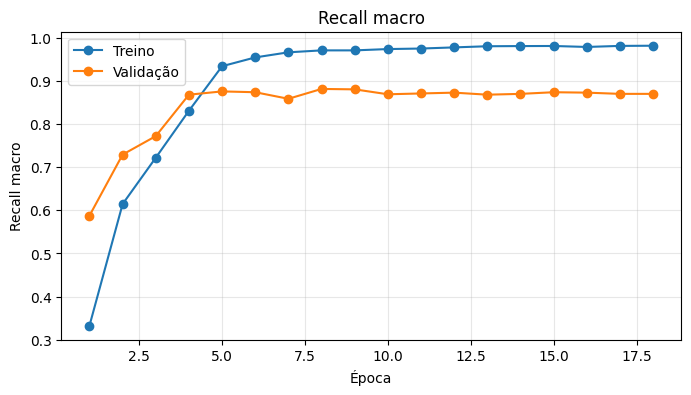

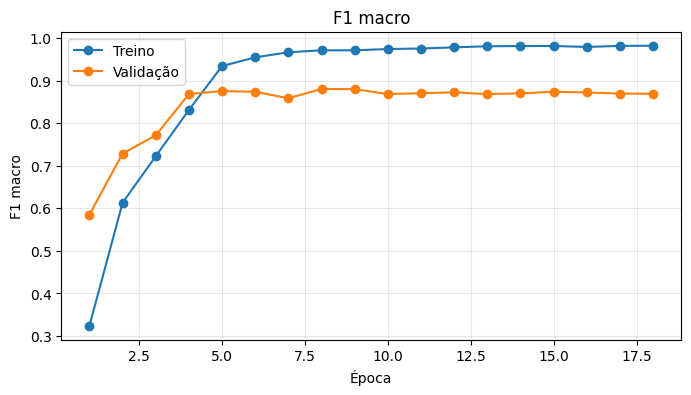

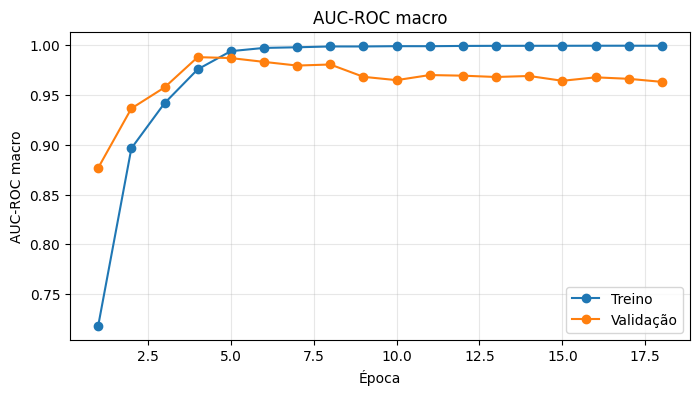

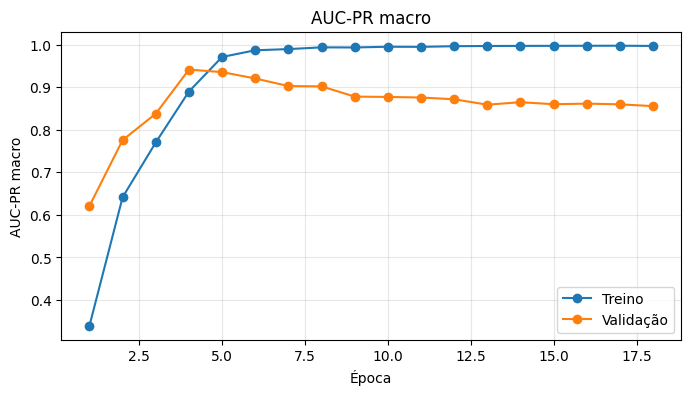

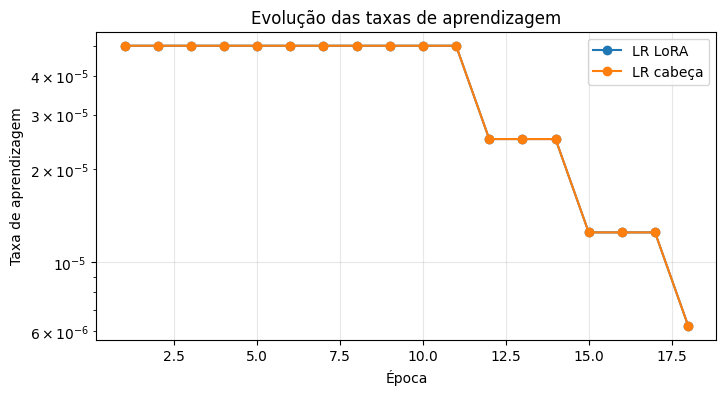

In [ ]:

history_df = pd.read_csv(HISTORY_PATH)

metric_labels = {
    "accuracy": "Accuracy",
    "precision": "Precision macro",
    "recall": "Recall macro",
    "f1": "F1 macro",
    "auc_roc": "AUC-ROC macro",
    "auc_pr": "AUC-PR macro",
}

for metric, label in metric_labels.items():
    plt.figure(figsize=(8, 4))
    plt.plot(
        history_df["epoch"],
        history_df[f"train_{metric}"],
        marker="o",
        label="Treino",
    )
    plt.plot(
        history_df["epoch"],
        history_df[f"val_{metric}"],
        marker="o",
        label="Validação",
    )
    plt.xlabel("Época")
    plt.ylabel(label)
    plt.title(label)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.show()

plt.figure(figsize=(8, 4))
plt.plot(
    history_df["epoch"],
    history_df["lr_lora"],
    marker="o",
    label="LR LoRA",
)
plt.plot(
    history_df["epoch"],
    history_df["lr_head"],
    marker="o",
    label="LR cabeça",
)
plt.xlabel("Época")
plt.ylabel("Taxa de aprendizagem")
plt.title("Evolução das taxas de aprendizagem")
plt.yscale("log")
plt.grid(alpha=0.3)
plt.legend()
plt.show()


## 11. Restauração do melhor checkpoint e avaliação no teste

In [ ]:

checkpoint = torch.load(
    BEST_CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False,
)

missing_keys, unexpected_keys = model.load_state_dict(
    checkpoint["state_dict"],
    strict=False,
)

print("Melhor época:", checkpoint["epoch"])
print("Métricas de validação do melhor checkpoint:")
for metric_name, metric_value in checkpoint["best_val_metrics"].items():
    print(f"  {metric_name}: {metric_value:.4f}")
print("Chaves inesperadas:", unexpected_keys)
print(
    "Chaves ausentes esperadas: pesos congelados do backbone, "
    f"total={len(missing_keys)}"
)

model.to(DEVICE)
model.eval()


Melhor época: 8
Métricas de validação do melhor checkpoint:
  accuracy: 0.8819
  precision: 0.8836
  recall: 0.8819
  f1: 0.8806
  auc_roc: 0.9808
  auc_pr: 0.9023
Chaves inesperadas: []
Chaves ausentes esperadas: pesos congelados do backbone, total=211


DINOv3LoRAClassifier(
  (backbone): PeftModel(
    (base_model): LoraModel(
      (model): DINOv3ViTModel(
        (embeddings): DINOv3ViTEmbeddings(
          (patch_embeddings): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
        )
        (rope_embeddings): DINOv3ViTRopePositionEmbedding()
        (model): DINOv3ViTEncoder(
          (layer): ModuleList(
            (0-11): 12 x DINOv3ViTLayer(
              (norm1): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
              (attention): DINOv3ViTAttention(
                (k_proj): lora.Linear(
                  (base_layer): Linear(in_features=768, out_features=768, bias=False)
                  (lora_dropout): ModuleDict(
                    (default): Dropout(p=0.2, inplace=False)
                  )
                  (lora_A): ModuleDict(
                    (default): Linear(in_features=768, out_features=16, bias=False)
                  )
                  (lora_B): ModuleDict(
                    (default)

In [ ]:

with torch.inference_mode():
    (
        train_final_metrics,
        train_final_targets,
        train_final_predictions,
        train_final_probabilities,
    ) = run_epoch(
        model=model,
        loader=train_eval_loader,
        optimizer=None,
    )

with torch.inference_mode():
    (
        test_metrics,
        test_targets,
        test_predictions,
        test_probabilities,
    ) = run_epoch(
        model=model,
        loader=test_loader,
        optimizer=None,
    )

print("Métricas finais do melhor checkpoint")
print(
    f"Acurácia do treino: "
    f"{train_final_metrics['accuracy']:.4f} "
    f"({100 * train_final_metrics['accuracy']:.2f}%)"
)
print(
    f"Acurácia do teste:  "
    f"{test_metrics['accuracy']:.4f} "
    f"({100 * test_metrics['accuracy']:.2f}%)"
)

print("\nMétricas macro no conjunto de teste")
print(f"Accuracy:  {test_metrics['accuracy']:.4f}")
print(f"Precision: {test_metrics['precision']:.4f}")
print(f"Recall:    {test_metrics['recall']:.4f}")
print(f"F1:        {test_metrics['f1']:.4f}")
print(f"AUC-ROC:   {test_metrics['auc_roc']:.4f}")
print(f"AUC-PR:    {test_metrics['auc_pr']:.4f}")


Avaliação:   0%|          | 0/154 [00:00<?, ?it/s]

Avaliação:   0%|          | 0/33 [00:00<?, ?it/s]

Métricas finais do melhor checkpoint
Acurácia do treino: 0.9745 (97.45%)
Acurácia do teste:  0.8257 (82.57%)

Métricas macro no conjunto de teste
Accuracy:  0.8257
Precision: 0.8646
Recall:    0.8257
F1:        0.8111
AUC-ROC:   0.9542
AUC-PR:    0.8771


In [ ]:

test_report_df = per_class_metrics_dataframe(
    test_targets,
    test_predictions,
    test_probabilities,
)

display(
    test_report_df.style.format({
        "precision": "{:.4f}",
        "recall": "{:.4f}",
        "f1": "{:.4f}",
        "auc_roc": "{:.4f}",
        "auc_pr": "{:.4f}",
    })
)


,classe,precision,recall,f1,auc_roc,auc_pr,suporte
0,Grade 0,0.7733,0.8867,0.8261,0.9820,0.8914,150
1,Grade 1,1.0000,0.8600,0.9247,0.9635,0.9156,150
2,Grade 2,0.9130,0.7000,0.7925,0.9348,0.8487,150
3,Grade 3,0.6608,1.0000,0.7958,0.9829,0.8939,150
4,Grade 4,0.7500,1.0000,0.8571,0.9837,0.8789,150
5,Grade 5,1.0000,0.3400,0.5075,0.8332,0.7134,150
6,Normal(Healthy skin),0.9551,0.9933,0.9739,0.9996,0.9978,150
7,macro avg,0.8646,0.8257,0.8111,0.9542,0.8771,1050
8,weighted avg,0.8646,0.8257,0.8111,0.9542,0.8771,1050


## 12. Matriz de confusão normalizada no conjunto de teste

,Grade 0,Grade 1,Grade 2,Grade 3,Grade 4,Grade 5,Normal(Healthy skin)
Grade 0,88.7%,0.0%,6.7%,0.0%,0.0%,0.0%,4.7%
Grade 1,14.0%,86.0%,0.0%,0.0%,0.0%,0.0%,0.0%
Grade 2,11.3%,0.0%,70.0%,18.7%,0.0%,0.0%,0.0%
Grade 3,0.0%,0.0%,0.0%,100.0%,0.0%,0.0%,0.0%
Grade 4,0.0%,0.0%,0.0%,0.0%,100.0%,0.0%,0.0%
Grade 5,0.0%,0.0%,0.0%,32.7%,33.3%,34.0%,0.0%
Normal(Healthy skin),0.7%,0.0%,0.0%,0.0%,0.0%,0.0%,99.3%


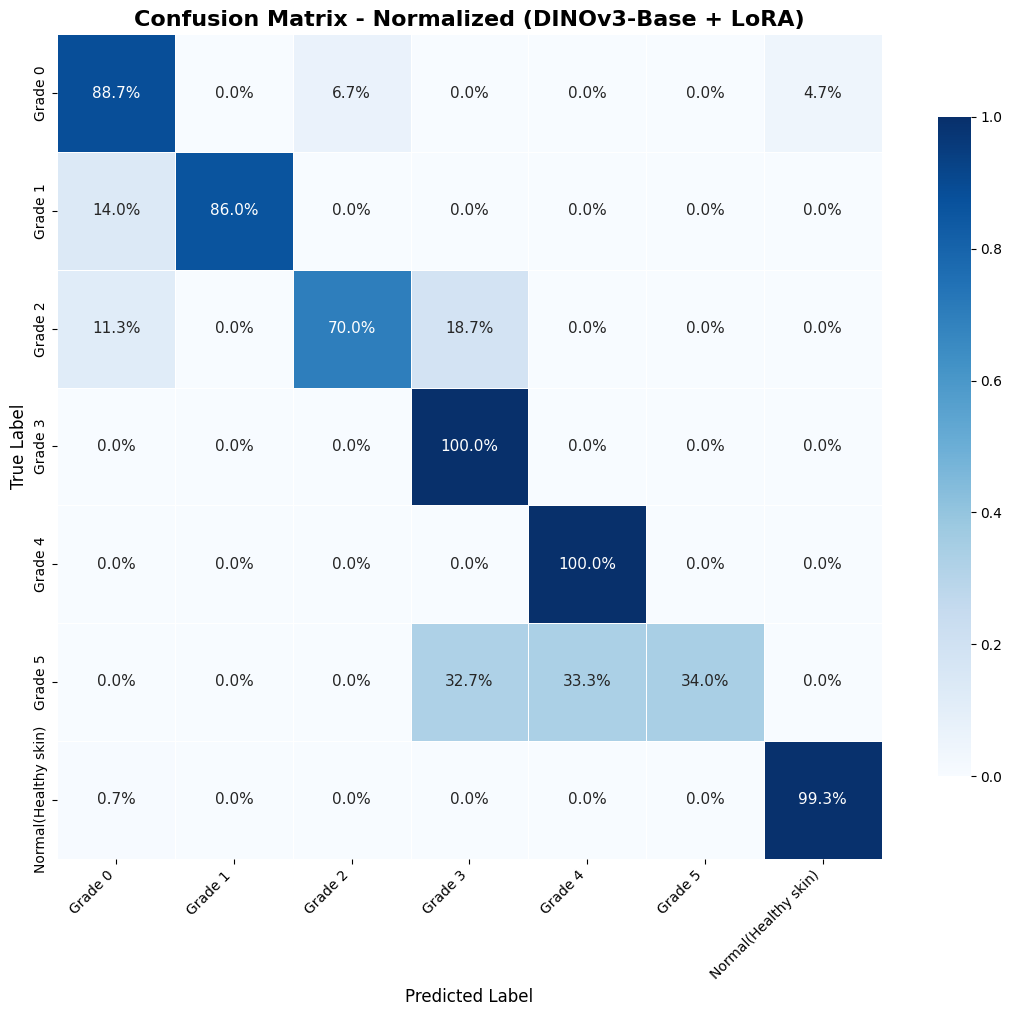

Matriz percentual em CSV: /content/drive/MyDrive/resultados_dinov3_lora_wagner/base/lora_qv_r8_warmup_v3_stable_large/confusion_matrix_test_percent.csv
Figura: /content/drive/MyDrive/resultados_dinov3_lora_wagner/base/lora_qv_r8_warmup_v3_stable_large/confusion_matrix_test_percent.png


In [ ]:
import seaborn as sns

CONFUSION_MATRIX_CSV_PATH = (
    OUTPUT_DIR / "confusion_matrix_test_percent.csv"
)

CONFUSION_MATRIX_PNG_PATH = (
    OUTPUT_DIR / "confusion_matrix_test_percent.png"
)

class_indices = list(range(NUM_CLASSES))

class_labels = [
    IDX_TO_CLASS[i]
    for i in class_indices
]

# Normaliza a matriz por classe real.
# Cada linha soma aproximadamente 100%.
cm_normalized = confusion_matrix(
    test_targets,
    test_predictions,
    labels=class_indices,
    normalize="true",
)

# Conversão para percentuais de 0 a 100 para o CSV.
cm_percent = cm_normalized * 100.0

cm_percent_df = pd.DataFrame(
    cm_percent,
    index=class_labels,
    columns=class_labels,
)

cm_percent_df.to_csv(
    CONFUSION_MATRIX_CSV_PATH,
    index_label="True Label",
)

display(
    cm_percent_df.style.format("{:.1f}%")
)

# Figura com o mesmo padrão visual da matriz do MobileNet-V2.
plt.figure(
    figsize=(12, 10)
)

ax = sns.heatmap(
    cm_normalized,
    annot=True,
    fmt=".1%",
    cmap="Blues",
    square=True,
    linewidths=0.5,
    xticklabels=class_labels,
    yticklabels=class_labels,
    vmin=0,
    vmax=1,
    cbar=True,
    cbar_kws={
        "shrink": 0.8,
    },
    annot_kws={
        "fontsize": 11,
    },
)

ax.set_title(
    "Confusion Matrix - Normalized (DINOv3-Base + LoRA)",
    fontsize=16,
    fontweight="bold",
)

ax.set_xlabel(
    "Predicted Label",
    fontsize=12,
)

ax.set_ylabel(
    "True Label",
    fontsize=12,
)

# Rótulos do eixo x inclinados em 45 graus.
plt.xticks(
    rotation=45,
    ha="right",
)

# Rótulos do eixo y rotacionados em 90 graus,
# reproduzindo o padrão da matriz do MobileNet-V2.
plt.yticks(
    rotation=90,
    va="center",
)

plt.tight_layout()

plt.savefig(
    CONFUSION_MATRIX_PNG_PATH,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print(
    "Matriz percentual em CSV:",
    CONFUSION_MATRIX_CSV_PATH,
)

print(
    "Figura:",
    CONFUSION_MATRIX_PNG_PATH,
)

## 13. Salvamento do adaptador LoRA, cabeça e metadados

In [ ]:

ADAPTER_DIR = OUTPUT_DIR / "lora_adapter"
HEAD_PATH = OUTPUT_DIR / "classifier_head.pt"
METADATA_PATH = OUTPUT_DIR / "metadata.json"
TEST_METRICS_PATH = OUTPUT_DIR / "test_metrics.csv"
TEST_PREDICTIONS_PATH = OUTPUT_DIR / "test_predictions.csv"

# save_pretrained salva apenas os adaptadores PEFT, sem duplicar
# todos os pesos congelados do DINOv3.
model.backbone.save_pretrained(ADAPTER_DIR)

torch.save(
    model.classifier.state_dict(),
    HEAD_PATH,
)

metadata = {
    "experiment_name": EXPERIMENT_NAME,
    "model_size": MODEL_SIZE,
    "model_id": MODEL_ID,
    "image_size": IMAGE_SIZE,
    "class_to_idx": CLASS_TO_IDX,
    "idx_to_class": {
        str(idx): name for idx, name in IDX_TO_CLASS.items()
    },
    "lora_rank": LORA_RANK,
    "lora_alpha": LORA_ALPHA,
    "lora_dropout": LORA_DROPOUT,
    "lora_target_modules": LORA_TARGET_MODULES,
    "head_warmup_epochs": HEAD_WARMUP_EPOCHS,
    "lr_lora_initial": LR_LORA,
    "lr_head_initial": LR_HEAD,
    "weight_decay": WEIGHT_DECAY,
    "label_smoothing": LABEL_SMOOTHING,
    "classifier_dropout": CLASSIFIER_DROPOUT,
    "best_epoch": int(checkpoint["epoch"]),
    "best_val_metrics": {
        key: float(value)
        for key, value in checkpoint["best_val_metrics"].items()
    },
    "train_accuracy": train_final_metrics["accuracy"],
    "test_accuracy": test_metrics["accuracy"],
    "test_precision_macro": test_metrics["precision"],
    "test_recall_macro": test_metrics["recall"],
    "test_f1_macro": test_metrics["f1"],
    "test_auc_roc_macro": test_metrics["auc_roc"],
    "test_auc_pr_macro": test_metrics["auc_pr"],
}

with open(METADATA_PATH, "w", encoding="utf-8") as file:
    json.dump(metadata, file, ensure_ascii=False, indent=2)

test_report_df.to_csv(TEST_METRICS_PATH, index=False)

test_paths = [path for path, _ in test_dataset.samples]
predictions_data = {
    "arquivo": test_paths,
    "classe_real": [IDX_TO_CLASS[i] for i in test_targets],
    "classe_predita": [IDX_TO_CLASS[i] for i in test_predictions],
}

# Salva também as probabilidades usadas nos cálculos de AUC.
for class_idx, class_name in IDX_TO_CLASS.items():
    safe_name = (
        class_name.lower()
        .replace(" ", "_")
        .replace("(", "")
        .replace(")", "")
    )
    predictions_data[f"prob_{safe_name}"] = test_probabilities[:, class_idx]

predictions_df = pd.DataFrame(predictions_data)
predictions_df.to_csv(TEST_PREDICTIONS_PATH, index=False)

print("Arquivos salvos:")
print("Adaptador LoRA:", ADAPTER_DIR)
print("Cabeça:", HEAD_PATH)
print("Metadados:", METADATA_PATH)
print("Métricas:", TEST_METRICS_PATH)
print("Predições e probabilidades:", TEST_PREDICTIONS_PATH)
print("Matriz de confusão CSV:", CONFUSION_MATRIX_CSV_PATH)
print("Matriz de confusão PNG:", CONFUSION_MATRIX_PNG_PATH)
print("Histórico:", HISTORY_PATH)


Arquivos salvos:
Adaptador LoRA: /content/drive/MyDrive/resultados_dinov3_lora_wagner/base/lora_qv_r8_warmup_v3_stable_large/lora_adapter
Cabeça: /content/drive/MyDrive/resultados_dinov3_lora_wagner/base/lora_qv_r8_warmup_v3_stable_large/classifier_head.pt
Metadados: /content/drive/MyDrive/resultados_dinov3_lora_wagner/base/lora_qv_r8_warmup_v3_stable_large/metadata.json
Métricas: /content/drive/MyDrive/resultados_dinov3_lora_wagner/base/lora_qv_r8_warmup_v3_stable_large/test_metrics.csv
Predições e probabilidades: /content/drive/MyDrive/resultados_dinov3_lora_wagner/base/lora_qv_r8_warmup_v3_stable_large/test_predictions.csv
Matriz de confusão CSV: /content/drive/MyDrive/resultados_dinov3_lora_wagner/base/lora_qv_r8_warmup_v3_stable_large/confusion_matrix_test_percent.csv
Matriz de confusão PNG: /content/drive/MyDrive/resultados_dinov3_lora_wagner/base/lora_qv_r8_warmup_v3_stable_large/confusion_matrix_test_percent.png
Histórico: /content/drive/MyDrive/resultados_dinov3_lora_wagner/ba

## 14. Recarregar o modelo salvo

In [ ]:

def load_saved_model(
    output_dir: Path,
    device: torch.device,
) -> tuple[nn.Module, dict]:
    with open(
        output_dir / "metadata.json",
        "r",
        encoding="utf-8",
    ) as file:
        metadata = json.load(file)

    base_backbone = AutoModel.from_pretrained(
        metadata["model_id"],
        torch_dtype=torch.float32,
    )

    adapted_backbone = PeftModel.from_pretrained(
        base_backbone,
        output_dir / "lora_adapter",
    )

    hidden_size = base_backbone.config.hidden_size
    loaded_model = DINOv3LoRAClassifier(
        backbone=adapted_backbone,
        hidden_size=hidden_size,
        num_classes=len(metadata["class_to_idx"]),
        dropout=float(metadata["classifier_dropout"]),
    )

    classifier_state = torch.load(
        output_dir / "classifier_head.pt",
        map_location="cpu",
        weights_only=True,
    )
    loaded_model.classifier.load_state_dict(classifier_state)

    loaded_model.to(device)
    loaded_model.eval()

    return loaded_model, metadata


# Exemplo:
# reloaded_model, reloaded_metadata = load_saved_model(OUTPUT_DIR, DEVICE)


## 15. Inferência em uma imagem

In [ ]:

def predict_image(
    image_path: str | Path,
    model: nn.Module,
) -> pd.DataFrame:
    image_path = Path(image_path)

    if not image_path.exists():
        raise FileNotFoundError(image_path)

    with Image.open(image_path) as image:
        image = image.convert("RGB")
        tensor = eval_transform(image).unsqueeze(0).to(DEVICE)

    with torch.inference_mode():
        with torch.autocast(
            device_type=DEVICE.type,
            dtype=AMP_DTYPE,
            enabled=USE_AMP,
        ):
            logits = model(tensor)

        probabilities = torch.softmax(
            logits.float(),
            dim=1,
        )[0].cpu().numpy()

    result = pd.DataFrame({
        "classe": CLASS_NAMES,
        "probabilidade": probabilities,
    }).sort_values(
        "probabilidade",
        ascending=False,
    ).reset_index(drop=True)

    return result


# Exemplo com a primeira imagem do conjunto de teste:
example_path = test_dataset.samples[0][0]
print("Imagem:", example_path)
display(predict_image(example_path, model))


Imagem: /content/perfect_balanced_dataset_wagner_v4_1000/teste/Grade 0/107.jpg


,classe,probabilidade
0,Grade 0,0.800338
1,Grade 1,0.104896
2,Grade 2,0.035575
3,Grade 4,0.026274
4,Normal(Healthy skin),0.014837
5,Grade 3,0.012923
6,Grade 5,0.005156
